In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

import cmocean
import seaborn as sns

In [3]:
plt.style.use("../../nice.mplstyle")

In [4]:
dslist = []
for version in [3, "3mft", 4]:
    xds = xr.open_zarr(f"runs/v{version}/inference-validation/forecast.zarr/")
    xds = xds.expand_dims({"version": [version]})
    dslist.append(xds)
ds = xr.concat(dslist, dim="version")

In [5]:
sds = open_anemoi_statistics()

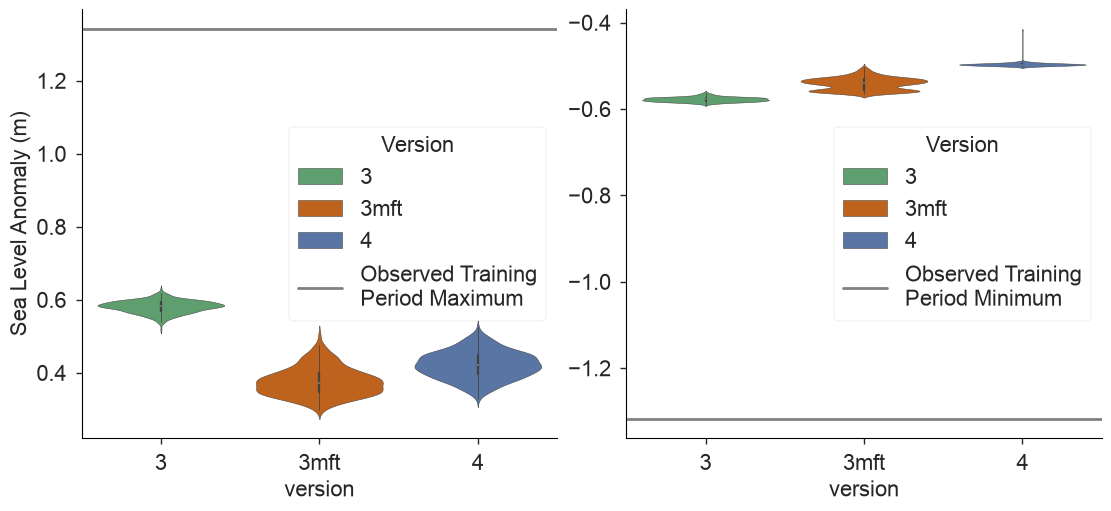

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5))


maxme = ds["sla"].isel(fhr=1).max("cell").compute()
minme = ds["sla"].isel(fhr=1).min("cell").compute()

for plotme, ax in zip([maxme, minme], axs):
    df = plotme.to_dataset().to_dataframe().reset_index()
    sns.violinplot(
        df,
        x="version",
        y="sla",
        hue="version",
        ax=ax,
    )

for plotme, loc, ax in zip(["maximum", "minimum"], ["lower left", "upper right"], axs):
    ax.axhline(
        sds[plotme].sel(variable="pooled"),
        color="gray",
        label=f"Observed Training\nPeriod {plotme.capitalize()}",
    )
    ax.legend(title="Version", loc="center right")
axs[0].set(ylabel = "Sea Level Anomaly (m)")
axs[1].set(ylabel = "")
fig.savefig(f"figures/maxmin_by_version.jpeg", dpi=300, bbox_inches="tight")

In [63]:
fraction = 0.6
plotme = ds.sla_filtered_cryosat_2.isel(fhr=0, t0=10)
observed = plotme.compute().dropna("cell")
n_obs=len(observed)
n_keep = np.floor(fraction * n_obs).astype(int)
obs_idx = np.random.permutation(np.asarray(observed.cell.values))
keep_cells = obs_idx[:n_keep]
selected = plotme.sel(cell=keep_cells)
#keep_cells = obs_idx.

In [64]:
len(selected)

2194

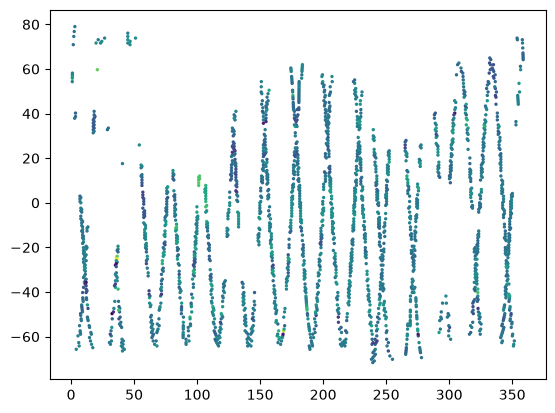

In [65]:
fig, ax = plt.subplots()
ax.scatter(
    ds.longitude.sel(cell=keep_cells),
    ds.latitude.sel(cell=keep_cells),
    c=selected,
    s=2
)